# LeNet-5 appliqué à la reconnaissance des caractères Tifinagh (AMHCD, 33 classes)

## 1. Données

In [1]:
import os, json, time, numpy as np, matplotlib
import matplotlib.pyplot as plt
from PIL import Image
matplotlib.rcParams['font.family'] = 'DejaVu Sans'   # contient les glyphes Tifinagh
matplotlib.rcParams['figure.dpi'] = 110
os.makedirs('figs', exist_ok=True)

# >>> A ADAPTER : dossier contenant les 33 sous-dossiers de classes (ya, yab, yach, ...)
DATA_ROOT  = '/home/claude/data/AMHCD_64/AMHCD_64'
LABEL_FILE = '/home/claude/data/labels/labels/sorted-33-common-tifinagh.txt'
SEED = 0
np.random.seed(SEED)

classes = sorted(os.listdir(DATA_ROOT))                      # noms latins (ya, yab, ...)
tifi    = [l.strip() for l in open(LABEL_FILE, encoding='utf-8') if l.strip()]
assert len(classes) == len(tifi) == 33
names = [f'{t} ({c})' for t, c in zip(tifi, classes)]

CACHE = 'tifinagh32.npz'
if os.path.exists(CACHE):
    d = np.load(CACHE); X, y = d['X'], d['y']
else:                                                          # RGB 64x64 -> niveaux de gris 32x32
    X, y = [], []
    for i, c in enumerate(classes):
        for f in sorted(os.listdir(f'{DATA_ROOT}/{c}')):
            im = Image.open(f'{DATA_ROOT}/{c}/{f}').convert('L').resize((32, 32), Image.BILINEAR)
            X.append(np.asarray(im, dtype=np.uint8)); y.append(i)
    X, y = np.stack(X), np.array(y); np.savez_compressed(CACHE, X=X, y=y)
print('Images :', X.shape, '| classes :', len(classes), '| images/classe : min', np.bincount(y).min(), 'max', np.bincount(y).max())

Images : (25740, 32, 32) | classes : 33 | images/classe : min 780 max 780


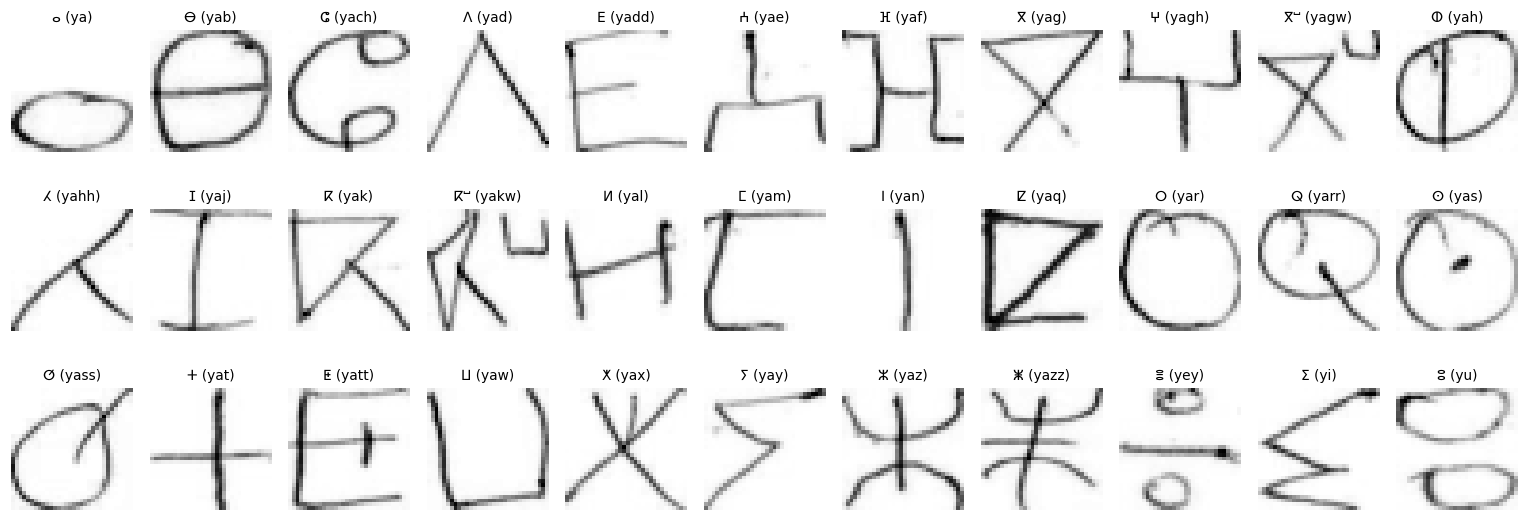

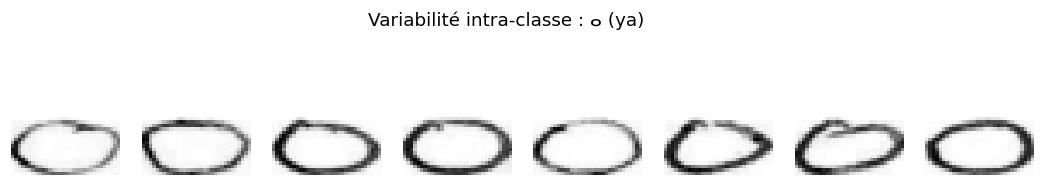

In [2]:
# Aperçu : un exemple par classe (glyphe Tifinagh + translittération)
fig, axs = plt.subplots(3, 11, figsize=(14, 5.2))
for i, ax in enumerate(axs.ravel()):
    ax.imshow(X[np.where(y == i)[0][0]], cmap='gray'); ax.set_title(names[i], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.savefig('figs/dataset_samples.png', dpi=130); plt.show()

# Variabilité intra-classe (un caractère, 8 écritures)
fig, axs = plt.subplots(1, 8, figsize=(12, 1.8))
idx = np.where(y == 0)[0][:8]
for a, k in zip(axs, idx): a.imshow(X[k], cmap='gray'); a.axis('off')
plt.suptitle(f'Variabilité intra-classe : {names[0]}', y=1.05); plt.savefig('figs/intra_class.png', dpi=130, bbox_inches='tight'); plt.show()

**Pré-traitement.** Les images originales (64×64, RGB mais en réalité en niveaux de gris, fond blanc) sont converties en niveaux de gris et redimensionnées en **32×32** (interpolation bilinéaire) pour correspondre à l'entrée de LeNet-5. L'encre est ensuite mise à 1 et le fond à 0 : $x \leftarrow 1 - x/255$, puis standardisation avec la moyenne et l'écart-type **du jeu d'apprentissage uniquement**.
**Découpage stratifié 70 / 15 / 15 %** (train / validation / test), graine fixée.

In [3]:
from sklearn.model_selection import train_test_split
idx = np.arange(len(y))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
i_va, i_te  = train_test_split(i_tmp, test_size=0.50, stratify=y[i_tmp], random_state=SEED)

Xf = 1.0 - X.astype(np.float64)/255.0
mu, sd = Xf[i_tr].mean(), Xf[i_tr].std()
Xn = ((Xf - mu)/sd)[:, None, :, :]                      # (N,1,32,32)
Xtr, ytr = Xn[i_tr], y[i_tr]; Xva, yva = Xn[i_va], y[i_va]; Xte, yte = Xn[i_te], y[i_te]
print(f'train {Xtr.shape} | val {Xva.shape} | test {Xte.shape} | mu={mu:.3f} sd={sd:.3f}')

train (18018, 1, 32, 32) | val (3861, 1, 32, 32) | test (3861, 1, 32, 32) | mu=0.071 sd=0.133


## 2. Bibliothèque LeNet-5 (couches, optimiseurs, apprentissage)

In [4]:
"""LeNet-5 en NumPy pur : couches parametrables, optimiseurs, entrainement."""
import numpy as np, time

### 2.1 Utilitaires `im2col` / `col2im`
La convolution est ramenée à un produit matriciel : chaque fenêtre $k\times k$ est dépliée en colonne (`im2col`), et le gradient est réparti par l'opération inverse (`col2im`).

In [5]:
# ---------- utilitaires im2col ----------
def im2col(x, k, stride=1, pad=0):
    N, C, H, W = x.shape
    if pad: x = np.pad(x, ((0,0),(0,0),(pad,pad),(pad,pad)))
    Ho = (H + 2*pad - k)//stride + 1; Wo = (W + 2*pad - k)//stride + 1
    s = x.strides
    v = np.lib.stride_tricks.as_strided(
        x, (N, C, k, k, Ho, Wo), (s[0], s[1], s[2], s[3], s[2]*stride, s[3]*stride))
    return v.reshape(N, C*k*k, Ho*Wo), Ho, Wo

def col2im(cols, xshape, k, stride=1, pad=0):
    N, C, H, W = xshape
    Ho = (H + 2*pad - k)//stride + 1; Wo = (W + 2*pad - k)//stride + 1
    cols = cols.reshape(N, C, k, k, Ho, Wo)
    out = np.zeros((N, C, H+2*pad, W+2*pad), dtype=cols.dtype)
    for i in range(k):
        for j in range(k):
            out[:, :, i:i+stride*Ho:stride, j:j+stride*Wo:stride] += cols[:, :, i, j]
    return out[:, :, pad:H+pad, pad:W+pad] if pad else out

### 2.2 Couches paramétrables
`Conv2D(in_ch, out_ch, k, stride, pad)`, `Pool2D(size, stride, mode='avg'|'max')`, `Dense`, `Activation('tanh'|'relu'|'sigmoid')`, `Dropout`, `Flatten`. Initialisation de He : $W\sim\mathcal N(0,2/n_{in})$.

In [6]:
# ---------- couches ----------
class Layer:
    params = ()
    def forward(self, x, train=True): raise NotImplementedError
    def backward(self, g): raise NotImplementedError

class Conv2D(Layer):
    def __init__(self, in_ch, out_ch, k, stride=1, pad=0, rng=None):
        rng = rng or np.random.default_rng(0)
        fan_in = in_ch*k*k
        self.W = rng.normal(0, np.sqrt(2.0/fan_in), (out_ch, in_ch, k, k))  # He
        self.b = np.zeros(out_ch)
        self.k, self.s, self.p = k, stride, pad
        self.dW = np.zeros_like(self.W); self.db = np.zeros_like(self.b)
    @property
    def params(self): return [(self.W, self.dW), (self.b, self.db)]
    def forward(self, x, train=True):
        cols, Ho, Wo = im2col(x, self.k, self.s, self.p)
        Wm = self.W.reshape(self.W.shape[0], -1)
        out = np.einsum('of,nfp->nop', Wm, cols, optimize=True) + self.b[None,:,None]
        self.cache = (x.shape, cols)
        return out.reshape(x.shape[0], -1, Ho, Wo)
    def backward(self, g):
        xshape, cols = self.cache
        N, O = g.shape[:2]
        g = g.reshape(N, O, -1)
        self.db[...] = g.sum(axis=(0,2))
        self.dW[...] = np.einsum('nop,nfp->of', g, cols, optimize=True).reshape(self.W.shape)
        Wm = self.W.reshape(O, -1)
        dcols = np.einsum('of,nop->nfp', Wm, g, optimize=True)
        return col2im(dcols, xshape, self.k, self.s, self.p)

class Pool2D(Layer):
    def __init__(self, size=2, stride=2, mode='avg'):
        self.k, self.s, self.mode = size, stride, mode
    def forward(self, x, train=True):
        N, C, H, W = x.shape
        cols, Ho, Wo = im2col(x.reshape(N*C, 1, H, W), self.k, self.s, 0)  # (NC, k*k, P)
        if self.mode == 'avg':
            out = cols.mean(axis=1); self.cache = (x.shape, None)
        else:
            self.idx = cols.argmax(axis=1); out = cols.max(axis=1); self.cache = (x.shape, cols.shape)
        return out.reshape(N, C, Ho, Wo)
    def backward(self, g):
        xshape, cshape = self.cache
        N, C, H, W = xshape
        gf = g.reshape(N*C, -1)
        kk = self.k*self.k
        if self.mode == 'avg':
            dcols = np.repeat(gf[:, None, :]/kk, kk, axis=1)
        else:
            dcols = np.zeros(cshape); 
            np.put_along_axis(dcols, self.idx[:, None, :], gf[:, None, :], axis=1)
        return col2im(dcols, (N*C, 1, H, W), self.k, self.s, 0).reshape(xshape)

class Flatten(Layer):
    def forward(self, x, train=True): self.shape = x.shape; return x.reshape(x.shape[0], -1)
    def backward(self, g): return g.reshape(self.shape)

class Dense(Layer):
    def __init__(self, n_in, n_out, rng=None):
        rng = rng or np.random.default_rng(0)
        self.W = rng.normal(0, np.sqrt(2.0/n_in), (n_in, n_out)); self.b = np.zeros(n_out)
        self.dW = np.zeros_like(self.W); self.db = np.zeros_like(self.b)
    @property
    def params(self): return [(self.W, self.dW), (self.b, self.db)]
    def forward(self, x, train=True): self.x = x; return x @ self.W + self.b
    def backward(self, g):
        self.dW[...] = self.x.T @ g; self.db[...] = g.sum(0); return g @ self.W.T

class Activation(Layer):
    def __init__(self, name='tanh'): self.name = name
    def forward(self, x, train=True):
        if self.name == 'tanh': self.y = np.tanh(x)
        elif self.name == 'relu': self.x = x; self.y = np.maximum(0, x)
        elif self.name == 'sigmoid': self.y = 1/(1+np.exp(-x))
        else: raise ValueError(self.name)
        return self.y
    def backward(self, g):
        if self.name == 'tanh': return g*(1-self.y**2)
        if self.name == 'relu': return g*(self.x > 0)
        return g*self.y*(1-self.y)

class Dropout(Layer):
    def __init__(self, p=0.5, rng=None): self.p = p; self.rng = rng or np.random.default_rng(1)
    def forward(self, x, train=True):
        if not train or self.p == 0: self.mask = None; return x
        self.mask = (self.rng.random(x.shape) >= self.p)/(1-self.p); return x*self.mask
    def backward(self, g): return g if self.mask is None else g*self.mask

### 2.3 Fonction de perte
Softmax + entropie croisée ; le gradient par rapport aux logits vaut $(p-\mathbf 1_y)/N$.

In [7]:
# ---------- perte ----------
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e/e.sum(1, keepdims=True)

def cross_entropy(logits, y):
    p = softmax(logits); N = len(y)
    loss = -np.log(p[np.arange(N), y] + 1e-12).mean()
    g = p.copy(); g[np.arange(N), y] -= 1
    return loss, g/N

### 2.4 Modèle `Sequential` et constructeur `build_lenet5`
`build_lenet5(...)` permet de choisir l'activation, le type de pooling, le nombre de filtres/neurones, le dropout.

In [8]:
# ---------- modele ----------
class Sequential:
    def __init__(self, layers): self.layers = layers
    def forward(self, x, train=True, keep=False):
        self.acts = []
        for l in self.layers:
            x = l.forward(x, train)
            if keep: self.acts.append(x.copy())
        return x
    def backward(self, g):
        for l in reversed(self.layers): g = l.backward(g)
    def params(self):
        return [p for l in self.layers for p in l.params]
    def n_params(self): return sum(p.size for p, _ in self.params())
    def predict(self, X, bs=512):
        out = [self.forward(X[i:i+bs], train=False) for i in range(0, len(X), bs)]
        return np.concatenate(out)

def build_lenet5(n_classes=33, in_ch=1, act='tanh', pool='avg', c1=6, c3=16, f5=120, f6=84,
                 k=5, dropout=0.0, seed=0):
    """LeNet-5 parametrable. 32x32 -> C1 -> S2 -> C3 -> S4 -> C5(120) -> F6(84) -> sortie."""
    rng = np.random.default_rng(seed)
    flat = c3*5*5
    L = [Conv2D(in_ch, c1, k, rng=rng), Activation(act), Pool2D(2, 2, pool),
         Conv2D(c1, c3, k, rng=rng), Activation(act), Pool2D(2, 2, pool),
         Flatten(), Dense(flat, f5, rng), Activation(act)]
    if dropout: L.append(Dropout(dropout, rng))
    L += [Dense(f5, f6, rng), Activation(act)]
    if dropout: L.append(Dropout(dropout, rng))
    L += [Dense(f6, n_classes, rng)]
    return Sequential(L)

### 2.5 Optimiseurs
SGD (avec momentum/Nesterov et weight decay optionnels), RMSprop, Adam.

In [9]:
# ---------- optimiseurs ----------
class Optimizer:
    def __init__(self, params, lr): self.params = params; self.lr = lr; self.t = 0
    def step(self): raise NotImplementedError

class SGD(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, nesterov=False, weight_decay=0.0):
        super().__init__(params, lr); self.m = momentum; self.nes = nesterov; self.wd = weight_decay
        self.v = [np.zeros_like(p) for p, _ in params]
    def step(self):
        for (p, g), v in zip(self.params, self.v):
            g = g + self.wd*p
            v *= self.m; v -= self.lr*g
            p += (self.m*v - self.lr*g) if self.nes else v

class RMSprop(Optimizer):
    def __init__(self, params, lr=1e-3, rho=0.9, eps=1e-8):
        super().__init__(params, lr); self.rho = rho; self.eps = eps
        self.s = [np.zeros_like(p) for p, _ in params]
    def step(self):
        for (p, g), s in zip(self.params, self.s):
            s *= self.rho; s += (1-self.rho)*g*g
            p -= self.lr*g/(np.sqrt(s)+self.eps)

class Adam(Optimizer):
    def __init__(self, params, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8, weight_decay=0.0):
        super().__init__(params, lr); self.b1, self.b2, self.eps, self.wd = b1, b2, eps, weight_decay
        self.m = [np.zeros_like(p) for p, _ in params]; self.v = [np.zeros_like(p) for p, _ in params]
    def step(self):
        self.t += 1
        for (p, g), m, v in zip(self.params, self.m, self.v):
            g = g + self.wd*p
            m *= self.b1; m += (1-self.b1)*g
            v *= self.b2; v += (1-self.b2)*g*g
            mh = m/(1-self.b1**self.t); vh = v/(1-self.b2**self.t)
            p -= self.lr*mh/(np.sqrt(vh)+self.eps)

def make_optimizer(name, params, **kw):
    return {'sgd': lambda: SGD(params, momentum=0.0, **kw),
            'momentum': lambda: SGD(params, **{'momentum':0.9, **kw}),
            'rmsprop': lambda: RMSprop(params, **kw),
            'adam': lambda: Adam(params, **kw)}[name]()

### 2.6 Fonction d'apprentissage
Boucle mini-batch avec mélange, augmentation optionnelle, décroissance exponentielle du pas, suivi train/validation.

In [10]:
# ---------- apprentissage ----------
def accuracy(model, X, y):
    return (model.predict(X).argmax(1) == y).mean()

def evaluate(model, X, y, bs=512):
    logits = model.predict(X, bs); 
    loss, _ = cross_entropy(logits, y); return loss, (logits.argmax(1) == y).mean()

def augment(xb, rng, max_shift=2):
    """Translation aleatoire (+-max_shift px) : amelioration (bonus)."""
    out = np.empty_like(xb); N = len(xb)
    sh = rng.integers(-max_shift, max_shift+1, (N, 2))
    for i in range(N):
        out[i] = np.roll(xb[i], (sh[i,0], sh[i,1]), axis=(1,2))
    return out

def train(model, opt, Xtr, ytr, Xva, yva, epochs=10, bs=64, seed=0, augment_fn=None,
          lr_decay=None, verbose=True):
    rng = np.random.default_rng(seed)
    hist = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[], 'time':[]}
    lr0 = opt.lr; t0 = time.time()
    for ep in range(epochs):
        if lr_decay: opt.lr = lr0*(lr_decay**ep)
        perm = rng.permutation(len(Xtr)); tl = 0; tc = 0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i+bs]; xb, yb = Xtr[idx], ytr[idx]
            if augment_fn: xb = augment_fn(xb, rng)
            logits = model.forward(xb, True)
            loss, g = cross_entropy(logits, yb)
            model.backward(g); opt.step()
            tl += loss*len(idx); tc += (logits.argmax(1) == yb).sum()
        vl, va = evaluate(model, Xva, yva)
        hist['train_loss'].append(tl/len(Xtr)); hist['train_acc'].append(tc/len(Xtr))
        hist['val_loss'].append(vl); hist['val_acc'].append(va); hist['time'].append(time.time()-t0)
        if verbose:
            print(f"ep {ep+1:2d}/{epochs} | loss {tl/len(Xtr):.4f} acc {tc/len(Xtr):.4f} | "
                  f"val_loss {vl:.4f} val_acc {va:.4f} | {time.time()-t0:.0f}s")
    return hist

### 2.7 Vérification numérique des gradients
Comparaison rétropropagation / différences centrées $\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$.

In [11]:
# ---------- verification des gradients ----------
def grad_check(model, x, y, n=5, eps=1e-5, seed=0):
    rng = np.random.default_rng(seed)
    loss, g = cross_entropy(model.forward(x, True), y); model.backward(g)
    worst = 0
    for p, dp in model.params():
        for _ in range(n):
            i = tuple(rng.integers(0, s) for s in p.shape)
            old = p[i]; p[i] = old+eps; lp, _ = cross_entropy(model.forward(x, True), y)
            p[i] = old-eps; lm, _ = cross_entropy(model.forward(x, True), y); p[i] = old
            num = (lp-lm)/(2*eps); ana = dp[i]
            worst = max(worst, abs(num-ana)/max(1e-8, abs(num)+abs(ana)))
    return worst

## 3. Vérification de l'implémentation

In [12]:
rng = np.random.default_rng(1)
xg, yg = Xtr[:4], ytr[:4]
for pool in ['avg', 'max']:
    for act in ['tanh', 'relu']:
        err = grad_check(build_lenet5(pool=pool, act=act), xg, yg)
        print(f'grad check  pool={pool:3s} act={act:4s} -> erreur relative max = {err:.2e}')

grad check  pool=avg act=tanh -> erreur relative max = 2.62e-08
grad check  pool=avg act=relu -> erreur relative max = 1.57e-08


grad check  pool=max act=tanh -> erreur relative max = 4.39e-09
grad check  pool=max act=relu -> erreur relative max = 2.06e-08


In [13]:
# Architecture : formes et nombre de paramètres couche par couche
model = build_lenet5()
x = Xtr[:2]; rows = []
names_l = {'Conv2D':'Conv','Pool2D':'Pool','Dense':'FC','Activation':'Act','Flatten':'Flatten','Dropout':'Dropout'}
print(f"{'couche':<12}{'sortie':<18}{'#params':>8}"); tot = 0
for l in model.layers:
    x = l.forward(x, False); n = sum(p.size for p, _ in l.params)
    tot += n
    if type(l).__name__ not in ('Activation',):
        print(f"{type(l).__name__:<12}{str(x.shape[1:]):<18}{n:>8}")
print('Total paramètres :', tot)

couche      sortie             #params
Conv2D      (6, 28, 28)            156
Pool2D      (6, 14, 14)              0
Conv2D      (16, 10, 10)          2416
Pool2D      (16, 5, 5)               0
Flatten     (400,)                   0
Dense       (120,)               48120
Dense       (84,)                10164
Dense       (33,)                 2805
Total paramètres : 63661


## 4. Modèle de référence : LeNet-5 (tanh, average pooling) + Adam
Hyper-paramètres : batch 64, Adam ($\eta=10^{-3}$, $\beta_1=0.9$, $\beta_2=0.999$), 15 époques. C'est l'architecture fidèle à l'énoncé (pooling moyen, activation tanh).

In [14]:
EPOCHS, BS = 15, 64
RUNS = {}      # nom -> dict(model, hist, test_acc, ...)

def run(name, opt_name, opt_kw, epochs=EPOCHS, augment_fn=None, lr_decay=None, **model_kw):
    print(f'\n=== {name} ===')
    m = build_lenet5(seed=SEED, **model_kw)
    opt = make_optimizer(opt_name, m.params(), **opt_kw)
    h = train(m, opt, Xtr, ytr, Xva, yva, epochs=epochs, bs=BS, seed=SEED, augment_fn=augment_fn, lr_decay=lr_decay)
    tl, ta = evaluate(m, Xte, yte)
    RUNS[name] = dict(model=m, hist=h, test_loss=float(tl), test_acc=float(ta), cfg=dict(opt=opt_name, **opt_kw, **model_kw, aug=augment_fn is not None, lr_decay=lr_decay))
    print(f'>>> TEST : loss {tl:.4f} | accuracy {ta:.4f} | temps {h["time"][-1]:.0f}s')
    open('progress.log','a').write(f'{name} done test_acc={ta:.4f}\n')
    return RUNS[name]

base = run('LeNet-5 (tanh, avg) + Adam', 'adam', dict(lr=1e-3))


=== LeNet-5 (tanh, avg) + Adam ===


ep  1/15 | loss 0.8555 acc 0.8123 | val_loss 0.3163 val_acc 0.9298 | 17s


ep  2/15 | loss 0.2170 acc 0.9512 | val_loss 0.1786 val_acc 0.9591 | 32s


ep  3/15 | loss 0.1211 acc 0.9713 | val_loss 0.1185 val_acc 0.9710 | 47s


ep  4/15 | loss 0.0770 acc 0.9831 | val_loss 0.0988 val_acc 0.9757 | 63s


...

ep 12/15 | loss 0.0064 acc 0.9992 | val_loss 0.0648 val_acc 0.9808 | 187s


ep 13/15 | loss 0.0063 acc 0.9994 | val_loss 0.0601 val_acc 0.9842 | 201s


ep 14/15 | loss 0.0060 acc 0.9992 | val_loss 0.0612 val_acc 0.9842 | 217s


ep 15/15 | loss 0.0045 acc 0.9995 | val_loss 0.0574 val_acc 0.9826 | 232s


>>> TEST : loss 0.0612 | accuracy 0.9837 | temps 232s


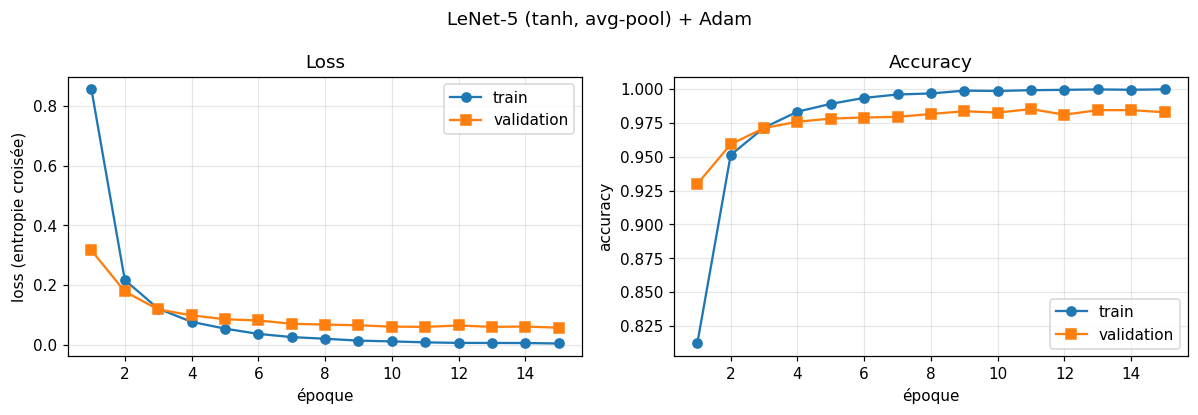

In [15]:
def plot_curves(h, title, fname=None):
    ep = np.arange(1, len(h['train_loss'])+1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ep, h['train_loss'], 'o-', label='train'); ax[0].plot(ep, h['val_loss'], 's-', label='validation')
    ax[0].set(xlabel='époque', ylabel='loss (entropie croisée)', title='Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, h['train_acc'], 'o-', label='train'); ax[1].plot(ep, h['val_acc'], 's-', label='validation')
    ax[1].set(xlabel='époque', ylabel='accuracy', title='Accuracy'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.suptitle(title); plt.tight_layout()
    if fname: plt.savefig(fname, dpi=130)
    plt.show()
plot_curves(base['hist'], 'LeNet-5 (tanh, avg-pool) + Adam', 'figs/curves_baseline.png')

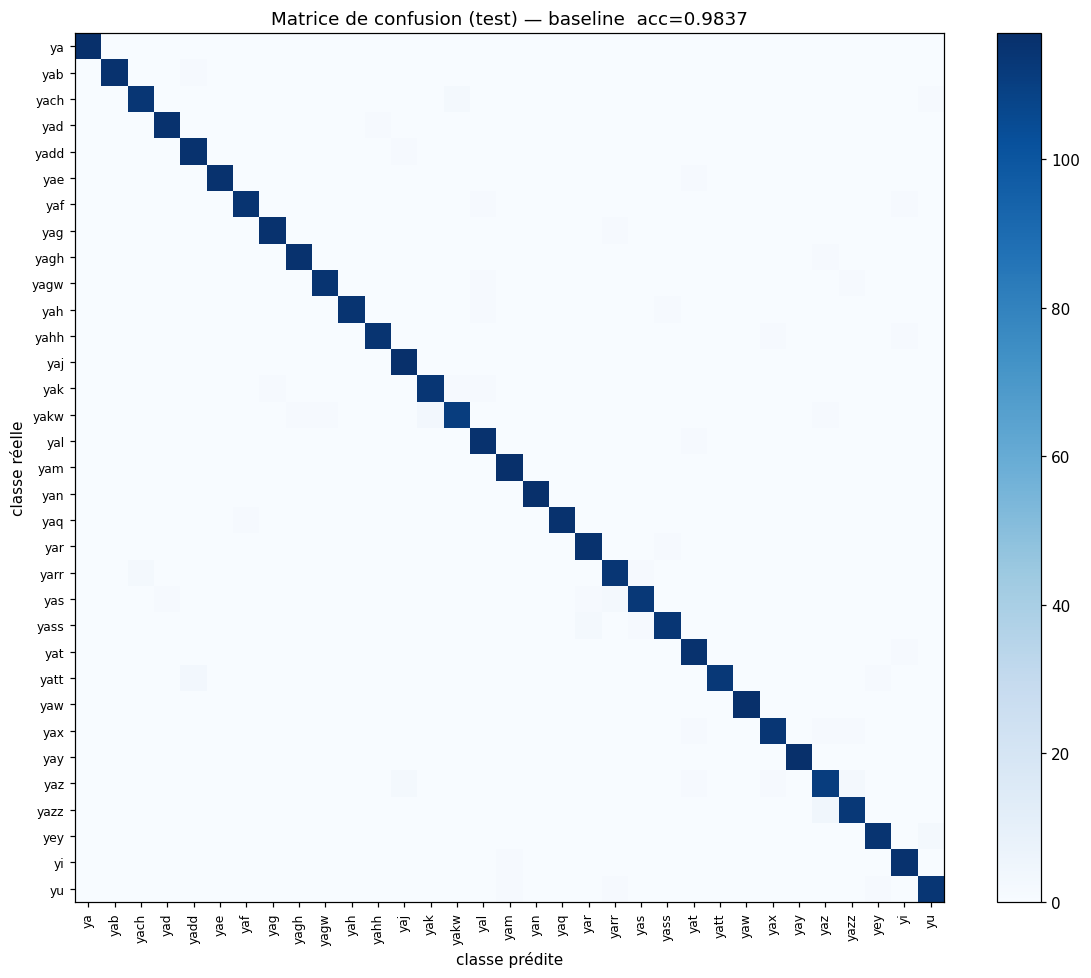

Plus fortes confusions (réel -> prédit : nb) :
     ⵥ (yazz) -> ⵣ (yaz)    : 4
     ⵟ (yatt) -> ⴹ (yadd)   : 3
    ⴽⵯ (yakw) -> ⴽ (yak)    : 3
      ⵣ (yaz) -> ⵥ (yazz)   : 2
     ⵚ (yass) -> ⵔ (yar)    : 2
      ⵣ (yaz) -> ⵊ (yaj)    : 2
      ⵙ (yas) -> ⵕ (yarr)   : 2
      ⴻ (yey) -> ⵓ (yu)     : 2
Classes les plus difficiles : ⴽⵯ (yakw) (94.87%), ⵣ (yaz) (94.87%), ⵙ (yas) (96.58%), ⵟ (yatt) (96.58%), ⵥ (yazz) (96.58%)


In [16]:
from sklearn.metrics import confusion_matrix, classification_report
def full_eval(run_dict, tag):
    m = run_dict['model']; pred = m.predict(Xte).argmax(1)
    cm = confusion_matrix(yte, pred, labels=range(33))
    fig, ax = plt.subplots(figsize=(10.5, 9))
    im = ax.imshow(cm, cmap='Blues'); plt.colorbar(im, fraction=0.046)
    ax.set_xticks(range(33)); ax.set_yticks(range(33))
    ax.set_xticklabels(classes, rotation=90, fontsize=8); ax.set_yticklabels(classes, fontsize=8)
    ax.set(xlabel='classe prédite', ylabel='classe réelle', title=f'Matrice de confusion (test) — {tag}  acc={run_dict["test_acc"]:.4f}')
    plt.tight_layout(); plt.savefig(f'figs/confusion_{tag}.png', dpi=130); plt.show()
    per = cm.diagonal()/cm.sum(1)
    off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:8], off.shape))[0]
    print('Plus fortes confusions (réel -> prédit : nb) :')
    for a, b in top:
        if off[a, b] > 0: print(f'   {names[a]:>10} -> {names[b]:<10} : {off[a,b]}')
    worst = np.argsort(per)[:5]
    print('Classes les plus difficiles :', ', '.join(f'{names[i]} ({per[i]:.2%})' for i in worst))
    return pred, cm, per
pred_b, cm_b, per_b = full_eval(base, 'baseline')

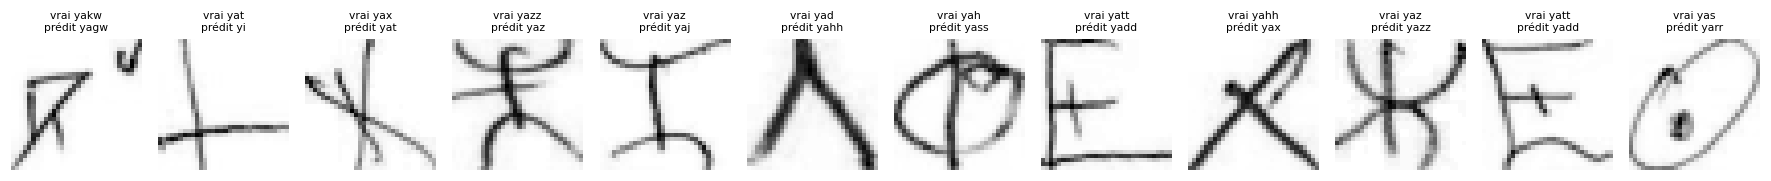

In [17]:
# Exemples mal classés
def show_errors(pred, tag, n=12):
    err = np.where(pred != yte)[0][:n]
    fig, axs = plt.subplots(1, max(len(err),1), figsize=(1.35*max(len(err),1), 2.1))
    for a, k in zip(np.atleast_1d(axs), err):
        a.imshow(Xte[k, 0], cmap='gray_r'); a.set_title(f'vrai {classes[yte[k]]}\nprédit {classes[pred[k]]}', fontsize=7); a.axis('off')
    plt.tight_layout(); plt.savefig(f'figs/errors_{tag}.png', dpi=130); plt.show()
show_errors(pred_b, 'baseline')

### Cartes caractéristiques (feature maps)
On propage une image de test et on affiche les sorties de **C1** (6 cartes 28×28 après activation), **S2** (6@14×14), **C3** (16@10×10) et **S4** (16@5×5), ainsi que les 6 filtres 5×5 appris par C1.

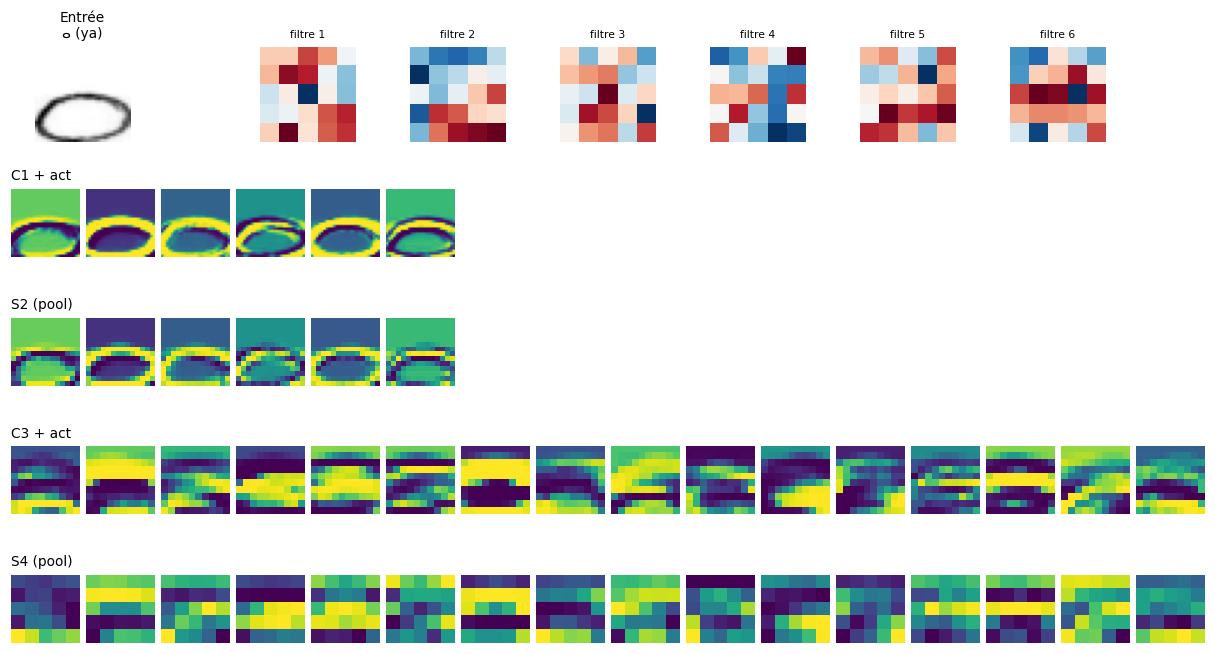

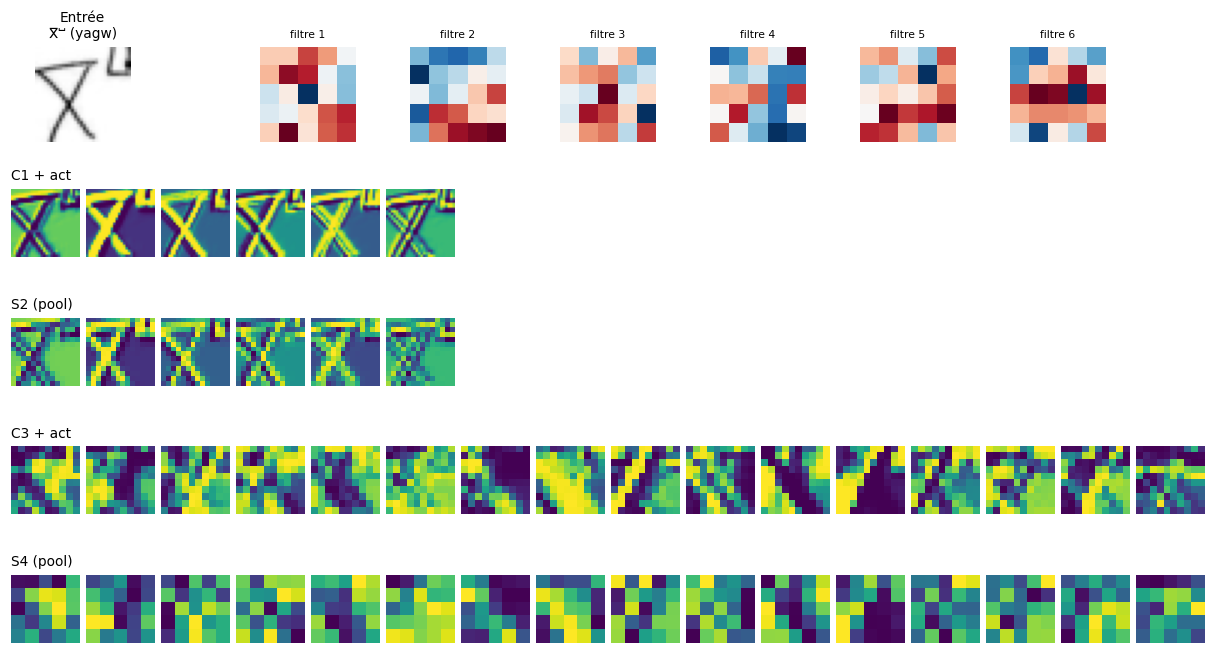

In [18]:
def show_feature_maps(model, x, label, tag):
    model.forward(x[None], train=False, keep=True)
    A = model.acts   # indices : 0 conv1,1 act1,2 pool1,3 conv2,4 act2,5 pool2
    stages = [('C1 + act', A[1][0]), ('S2 (pool)', A[2][0]), ('C3 + act', A[4][0]), ('S4 (pool)', A[5][0])]
    fig = plt.figure(figsize=(14, 7.2)); gs = fig.add_gridspec(5, 16, hspace=0.35, wspace=0.1)
    ax = fig.add_subplot(gs[0, 0:2]); ax.imshow(x[0], cmap='gray_r'); ax.set_title(f'Entrée\n{label}', fontsize=9); ax.axis('off')
    W = model.layers[0].W
    for j in range(W.shape[0]):
        a = fig.add_subplot(gs[0, 3+j*2:5+j*2]); a.imshow(W[j, 0], cmap='RdBu_r'); a.set_title(f'filtre {j+1}', fontsize=7); a.axis('off')
    for r, (nm, fm) in enumerate(stages, start=1):
        for j in range(fm.shape[0]):
            a = fig.add_subplot(gs[r, j]); a.imshow(fm[j], cmap='viridis'); a.axis('off')
            if j == 0: a.set_title(nm, fontsize=9, loc='left')
    plt.savefig(f'figs/featuremaps_{tag}.png', dpi=130, bbox_inches='tight'); plt.show()
k = np.where(yte == 0)[0][0]
show_feature_maps(base['model'], Xte[k], names[0], 'baseline')
k2 = np.where(yte == 9)[0][0]
show_feature_maps(base['model'], Xte[k2], names[9], 'baseline_b')

## 5. Comparaison des optimiseurs
Même architecture (tanh, avg-pool), même initialisation et même découpage ; seuls l'optimiseur et son pas changent. Le pas de chaque optimiseur a été choisi parmi des valeurs usuelles (pas de recherche exhaustive).

In [19]:
run('SGD (lr=0.05)', 'sgd', dict(lr=0.05))
run('SGD + Momentum (lr=0.01, m=0.9)', 'momentum', dict(lr=0.01))
run('RMSprop (lr=1e-3)', 'rmsprop', dict(lr=1e-3))
RUNS['Adam (lr=1e-3)'] = RUNS['LeNet-5 (tanh, avg) + Adam']
opt_names = ['SGD (lr=0.05)', 'SGD + Momentum (lr=0.01, m=0.9)', 'RMSprop (lr=1e-3)', 'Adam (lr=1e-3)']


=== SGD (lr=0.05) ===


ep  1/15 | loss 1.1975 acc 0.7466 | val_loss 0.5685 val_acc 0.8881 | 15s


ep  2/15 | loss 0.4351 acc 0.9093 | val_loss 0.3513 val_acc 0.9251 | 30s


ep  3/15 | loss 0.2877 acc 0.9386 | val_loss 0.2562 val_acc 0.9435 | 46s


ep  4/15 | loss 0.2150 acc 0.9529 | val_loss 0.2079 val_acc 0.9542 | 63s


...

ep 12/15 | loss 0.0044 acc 0.9989 | val_loss 0.0627 val_acc 0.9847 | 186s


ep 13/15 | loss 0.0031 acc 0.9994 | val_loss 0.0669 val_acc 0.9837 | 202s


ep 14/15 | loss 0.0022 acc 0.9995 | val_loss 0.0750 val_acc 0.9816 | 216s


ep 15/15 | loss 0.0022 acc 0.9993 | val_loss 0.0700 val_acc 0.9839 | 232s


>>> TEST : loss 0.0769 | accuracy 0.9808 | temps 232s


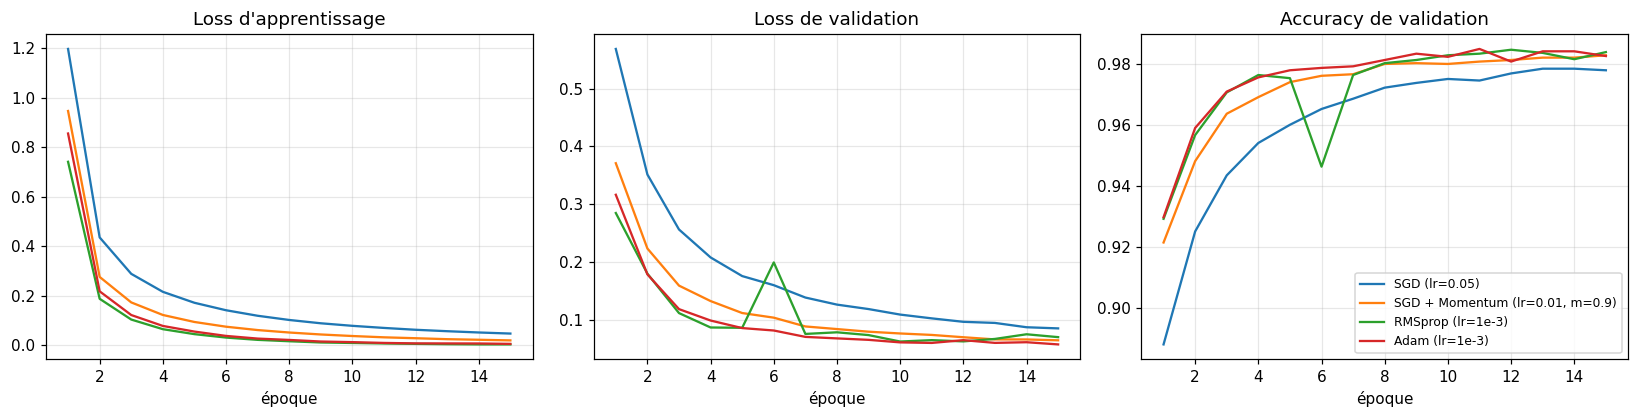

optimiseur                           val acc (fin)  test acc  test loss  temps (s)
SGD (lr=0.05)                               0.9780    0.9782     0.0820        231
SGD + Momentum (lr=0.01, m=0.9)             0.9829    0.9845     0.0625        229
RMSprop (lr=1e-3)                           0.9839    0.9808     0.0769        232
Adam (lr=1e-3)                              0.9826    0.9837     0.0612        232


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
for n in opt_names:
    h = RUNS[n]['hist']; ep = np.arange(1, len(h['val_acc'])+1)
    ax[0].plot(ep, h['train_loss'], label=n); ax[1].plot(ep, h['val_loss'], label=n); ax[2].plot(ep, h['val_acc'], label=n)
ax[0].set(title='Loss d\'apprentissage', xlabel='époque'); ax[1].set(title='Loss de validation', xlabel='époque'); ax[2].set(title='Accuracy de validation', xlabel='époque')
for a in ax: a.grid(alpha=.3)
ax[2].legend(fontsize=8); plt.tight_layout(); plt.savefig('figs/optimizers.png', dpi=130); plt.show()
print(f"{'optimiseur':<36}{'val acc (fin)':>14}{'test acc':>10}{'test loss':>11}{'temps (s)':>11}")
for n in opt_names:
    r = RUNS[n]; print(f"{n:<36}{r['hist']['val_acc'][-1]:>14.4f}{r['test_acc']:>10.4f}{r['test_loss']:>11.4f}{r['hist']['time'][-1]:>11.0f}")

## 6. Améliorations (bonus)
On part de la référence Adam et on modifie un élément à la fois :
1. **ReLU + max-pooling** à la place de tanh + average-pooling ;
2. **+ augmentation de données** (translations aléatoires de ±2 px) et **décroissance exponentielle du pas** ($\eta_t=\eta_0\,0.9^t$) ;
3. **+ Dropout 0.3** sur les couches fully connected.

In [21]:
run('ReLU + max-pool', 'adam', dict(lr=1e-3), act='relu', pool='max')
run('ReLU + max-pool + augmentation + decay', 'adam', dict(lr=1e-3), act='relu', pool='max', augment_fn=augment, lr_decay=0.9)
run('ReLU + max-pool + aug + decay + dropout 0.3', 'adam', dict(lr=1e-3), act='relu', pool='max', augment_fn=augment, lr_decay=0.9, dropout=0.3)
imp_names = ['LeNet-5 (tanh, avg) + Adam', 'ReLU + max-pool', 'ReLU + max-pool + augmentation + decay', 'ReLU + max-pool + aug + decay + dropout 0.3']


=== ReLU + max-pool ===


ep  1/15 | loss 0.9789 acc 0.7449 | val_loss 0.3153 val_acc 0.9130 | 16s


ep  2/15 | loss 0.2003 acc 0.9439 | val_loss 0.1844 val_acc 0.9490 | 32s


ep  3/15 | loss 0.1223 acc 0.9637 | val_loss 0.1373 val_acc 0.9606 | 49s


ep  4/15 | loss 0.0719 acc 0.9804 | val_loss 0.1250 val_acc 0.9676 | 65s


...

ep 12/15 | loss 0.2121 acc 0.9371 | val_loss 0.0689 val_acc 0.9785 | 204s


ep 13/15 | loss 0.1994 acc 0.9407 | val_loss 0.0638 val_acc 0.9806 | 223s


ep 14/15 | loss 0.1966 acc 0.9421 | val_loss 0.0627 val_acc 0.9824 | 241s


ep 15/15 | loss 0.1934 acc 0.9437 | val_loss 0.0622 val_acc 0.9806 | 258s


>>> TEST : loss 0.0708 | accuracy 0.9803 | temps 258s


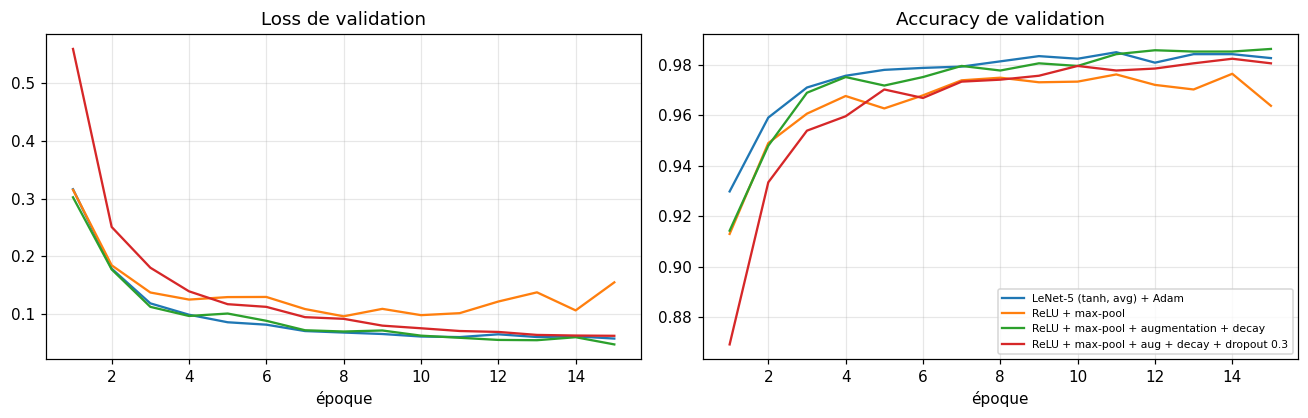

variante                                         train acc  val acc  test acc  écart train-val
LeNet-5 (tanh, avg) + Adam                          0.9995   0.9826    0.9837           0.0169
ReLU + max-pool                                     0.9901   0.9637    0.9666           0.0264
ReLU + max-pool + augmentation + decay              0.9862   0.9863    0.9845          -0.0000
ReLU + max-pool + aug + decay + dropout 0.3         0.9437   0.9806    0.9803          -0.0369

Meilleur modèle (sélection sur validation) : ReLU + max-pool + augmentation + decay


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
for n in imp_names:
    h = RUNS[n]['hist']; ep = np.arange(1, len(h['val_acc'])+1)
    ax[0].plot(ep, h['val_loss'], label=n); ax[1].plot(ep, h['val_acc'], label=n)
ax[0].set(title='Loss de validation', xlabel='époque'); ax[1].set(title='Accuracy de validation', xlabel='époque')
for a in ax: a.grid(alpha=.3)
ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig('figs/improvements.png', dpi=130); plt.show()
print(f"{'variante':<48}{'train acc':>10}{'val acc':>9}{'test acc':>10}{'écart train-val':>17}")
for n in imp_names:
    r = RUNS[n]; h = r['hist']
    print(f"{n:<48}{h['train_acc'][-1]:>10.4f}{h['val_acc'][-1]:>9.4f}{r['test_acc']:>10.4f}{h['train_acc'][-1]-h['val_acc'][-1]:>17.4f}")
best_name = max(imp_names, key=lambda n: RUNS[n]['hist']['val_acc'][-1])   # sélection sur la VALIDATION
print('\nMeilleur modèle (sélection sur validation) :', best_name)

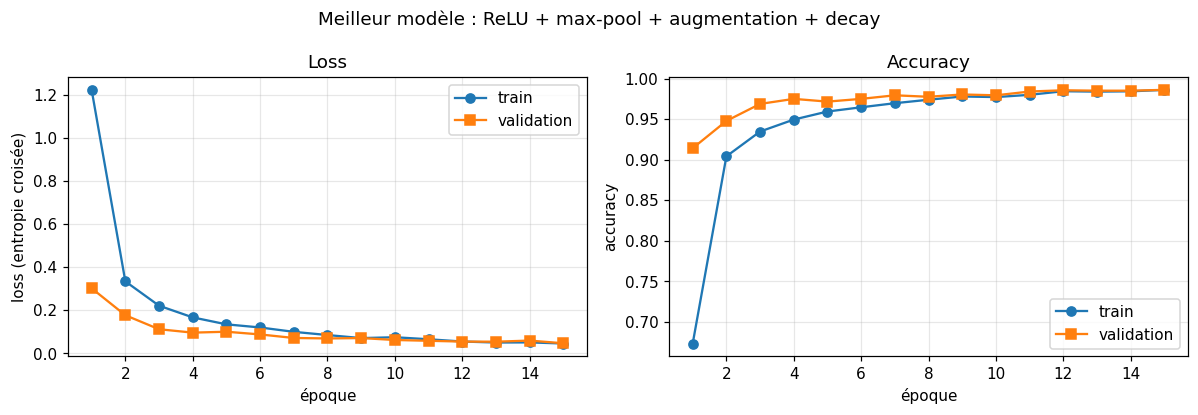

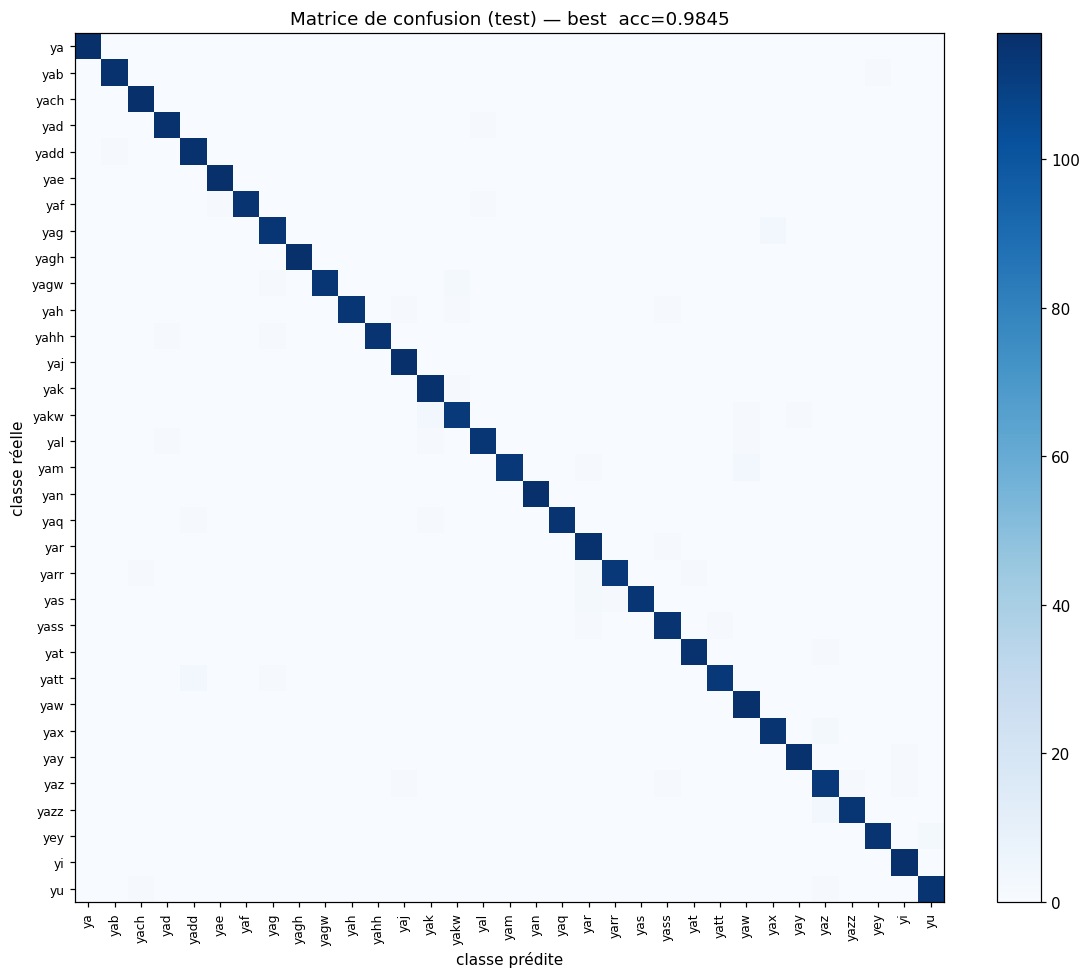

Plus fortes confusions (réel -> prédit : nb) :
     ⵥ (yazz) -> ⵣ (yaz)    : 3
     ⵟ (yatt) -> ⴹ (yadd)   : 3
    ⴽⵯ (yakw) -> ⴽ (yak)    : 3
      ⵎ (yam) -> ⵡ (yaw)    : 3
      ⴳ (yag) -> ⵅ (yax)    : 3
      ⵙ (yas) -> ⵔ (yar)    : 2
      ⵅ (yax) -> ⵣ (yaz)    : 2
     ⵕ (yarr) -> ⵔ (yar)    : 2
Classes les plus difficiles : ⴽⵯ (yakw) (95.73%), ⵣ (yaz) (96.58%), ⵕ (yarr) (96.58%), ⵎ (yam) (96.58%), ⵟ (yatt) (96.58%)


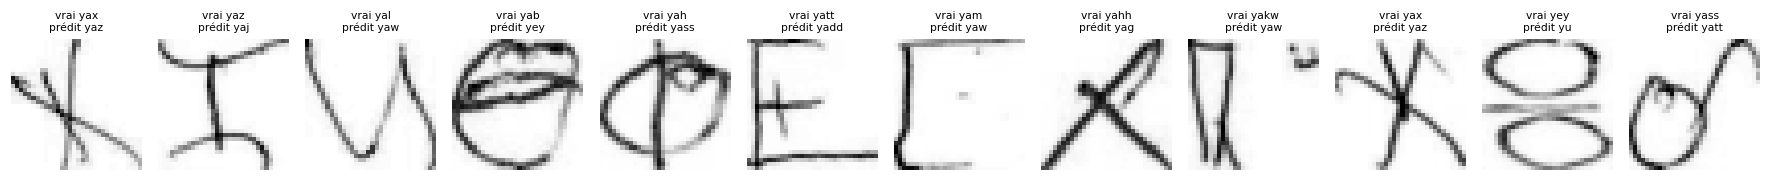

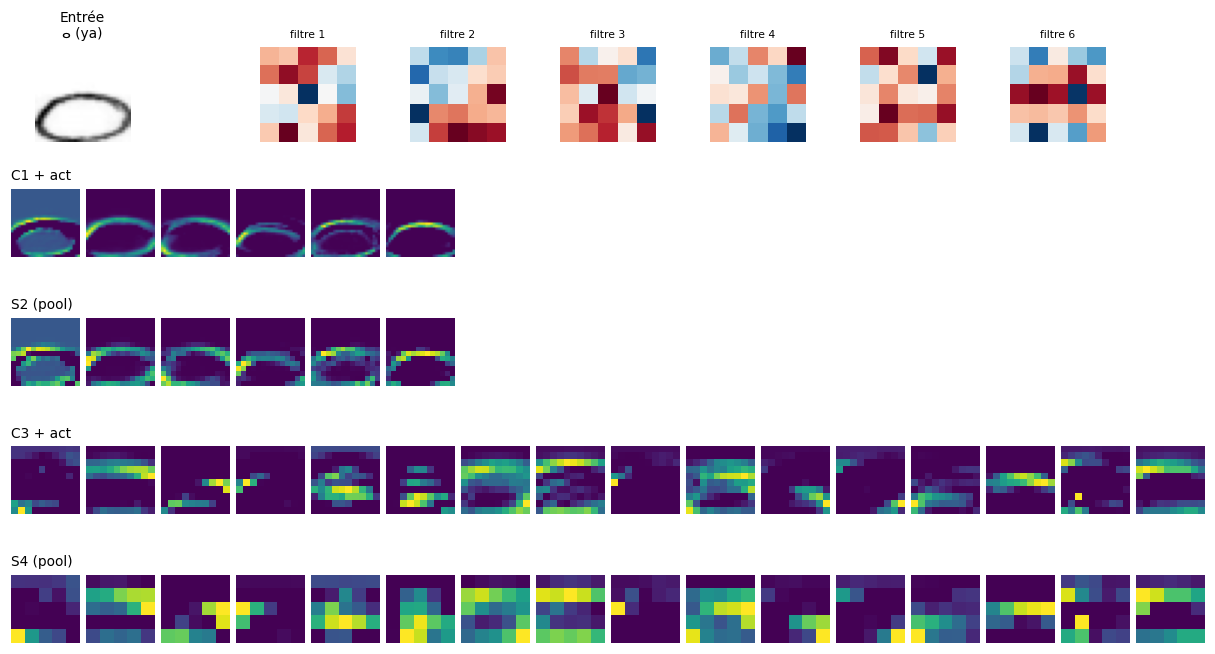

In [23]:
best = RUNS[best_name]
plot_curves(best['hist'], f'Meilleur modèle : {best_name}', 'figs/curves_best.png')
pred_v, cm_v, per_v = full_eval(best, 'best')
show_errors(pred_v, 'best')
show_feature_maps(best['model'], Xte[k], names[0], 'best')

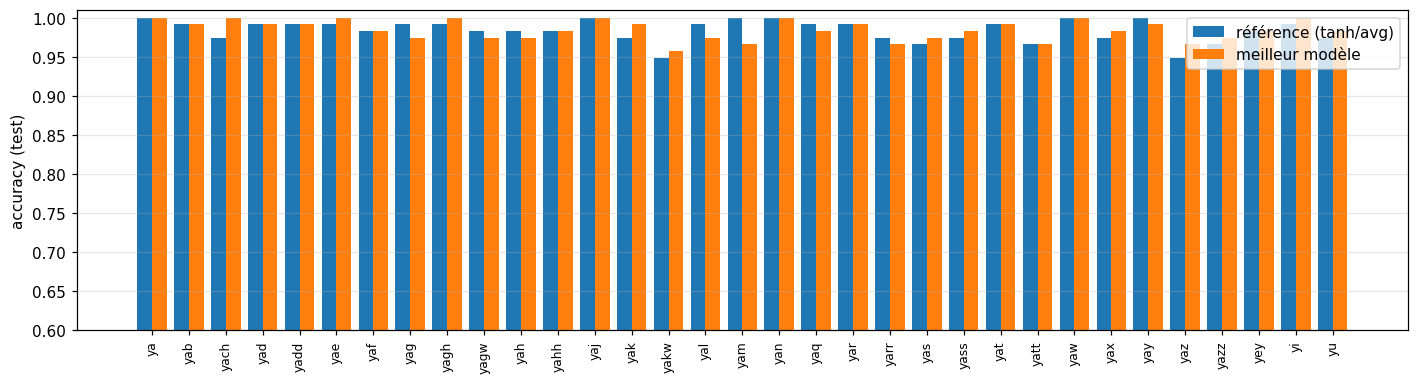

              precision    recall  f1-score   support

          ya      1.000     1.000     1.000       117
         yab      0.991     0.991     0.991       117
        yach      0.983     1.000     0.992       117
         yad      0.983     0.991     0.987       117
        yadd      0.967     0.991     0.979       117
         yae      0.992     1.000     0.996       117
         yaf      1.000     0.983     0.991       117
         yag      0.974     0.974     0.974       117
        yagh      1.000     1.000     1.000       117
        yagw      1.000     0.974     0.987       117
         yah      1.000     0.974     0.987       117
        yahh      1.000     0.983     0.991       117
         yaj      0.983     1.000     0.992       117
         yak      0.959     0.991     0.975       117
        yakw      0.966     0.957     0.961       117
         yal      0.983     0.974     0.979       117
         yam      1.000     0.966     0.983       117
         yan      1.000    

In [24]:
# Accuracy par classe : référence vs meilleur modèle
fig, ax = plt.subplots(figsize=(13, 3.6)); w = 0.4; xs = np.arange(33)
ax.bar(xs-w/2, per_b, w, label='référence (tanh/avg)'); ax.bar(xs+w/2, per_v, w, label='meilleur modèle')
ax.set_xticks(xs); ax.set_xticklabels(classes, rotation=90, fontsize=8); ax.set_ylim(0.6, 1.01); ax.set_ylabel('accuracy (test)'); ax.legend(); ax.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.savefig('figs/per_class.png', dpi=130); plt.show()
print(classification_report(yte, pred_v, target_names=classes, digits=3))

## 7. Synthèse et sauvegarde des résultats

In [25]:
summary = {n: dict(test_acc=r['test_acc'], test_loss=r['test_loss'], val_acc=float(r['hist']['val_acc'][-1]), train_acc=float(r['hist']['train_acc'][-1]),
                   time_s=float(r['hist']['time'][-1]), cfg={k: (v if not callable(v) else str(v)) for k, v in r['cfg'].items()}) for n, r in RUNS.items()}
summary['_meta'] = dict(n_params=int(build_lenet5().n_params()), n_train=int(len(ytr)), n_val=int(len(yva)), n_test=int(len(yte)), epochs=EPOCHS, batch=BS, best=best_name)
summary['_hist'] = {n: {k: [float(v) for v in vals] for k, vals in r['hist'].items()} for n, r in RUNS.items()}
summary['_per_class'] = {'classes': classes, 'baseline': [float(v) for v in per_b], 'best': [float(v) for v in per_v]}
json.dump(summary, open('results.json', 'w'), indent=1)
print(f"{'configuration':<48}{'test acc':>9}")
for n, r in RUNS.items(): print(f"{n:<48}{r['test_acc']:>9.4f}")

configuration                                    test acc
LeNet-5 (tanh, avg) + Adam                         0.9837
SGD (lr=0.05)                                      0.9782
SGD + Momentum (lr=0.01, m=0.9)                    0.9845
RMSprop (lr=1e-3)                                  0.9808
Adam (lr=1e-3)                                     0.9837
ReLU + max-pool                                    0.9666
ReLU + max-pool + augmentation + decay             0.9845
ReLU + max-pool + aug + decay + dropout 0.3        0.9803
